# MMM Stress Test 06 — Omitted Confounders

**Question:** How much can one missing business driver distort media attribution?

**Stress variable:** Promotion-to-Meta-spend correlation eta (0.0 → 1.0)  
**Key result:** As eta rises, Model B (omits promo) increasingly overestimates Meta ROAS.  
Model A (includes promo) remains well-recovered regardless of eta.  

**Core insight:** The control variable does not need to be 'marketing' to change marketing attribution.

---
Self-contained: numpy, pandas, matplotlib, statsmodels only.

## Section 1 — Configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

# ── True parameters ──────────────────────────────────────────────────────────
TRUE_ROAS = {'meta': 2.0, 'search': 5.0, 'tv': 1.5}
N_WEEKS   = 156
NOISE_SD  = 60_000

# ── Stress levels ─────────────────────────────────────────────────────────────
ETA_LEVELS = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]

# ── Promo parameters ──────────────────────────────────────────────────────────
PROMO_PROB          = 0.10      # promotion in ~10% of weeks
PROMO_REVENUE_LIFT  = 400_000  # promo direct revenue lift
PROMO_META_BASE     = 30_000   # additional Meta spend during promo (scaled by eta)

# ── Monte Carlo sizes ─────────────────────────────────────────────────────────
N_BASELINE = 500
N_STRESS   = 300

MASTER_SEED = 20260831

print('Configuration loaded.')
print(f'TRUE_ROAS   : {TRUE_ROAS}')
print(f'ETA_LEVELS  : {ETA_LEVELS}')
print(f'N_WEEKS={N_WEEKS}  NOISE_SD={NOISE_SD:,}')

Configuration loaded.
TRUE_ROAS   : {'meta': 2.0, 'search': 5.0, 'tv': 1.5}
ETA_LEVELS  : [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
N_WEEKS=156  NOISE_SD=60,000


## Section 2 — Data-Generating Process

In [2]:
def generate_data(eta: float, seed: int, n_weeks: int = N_WEEKS, noise_sd: float = NOISE_SD) -> tuple:
    """
    Generate synthetic MMM data with a correlated omitted confounder (promotions).

    eta = 0  →  promo has no effect on Meta spend  (clean case)
    eta > 0  →  promo boosts Meta spend by eta * PROMO_META_BASE

    Both models observe: trend, sin52, cos52, meta, search, tv
    Model A also includes: promo                    (correctly specified)
    Model B does NOT include promo                  (misspecified)

    True causal ROAS for all channels is always [2.0, 5.0, 1.5].

    Returns
    -------
    df    : pd.DataFrame
    truth : dict
    """
    rng = np.random.default_rng(seed)
    t   = np.arange(n_weeks)

    # ── Promotions (exogenous event, 10% of weeks) ────────────────────────────
    promo = rng.binomial(1, PROMO_PROB, n_weeks).astype(float)

    # ── Promo effect on revenue ────────────────────────────────────────────────
    promo_effect_on_revenue = PROMO_REVENUE_LIFT * promo

    # ── Promo effect on Meta spend (the confounder relationship) ─────────────
    promo_effect_on_meta = eta * PROMO_META_BASE * promo

    # ── Media spend ───────────────────────────────────────────────────────────
    meta   = np.clip(55_000 + 22_000 * rng.standard_normal(n_weeks) + promo_effect_on_meta, 5_000, None)
    search = np.clip(42_000 + 16_000 * rng.standard_normal(n_weeks), 5_000, None)
    tv     = np.clip(90_000 + 45_000 * rng.standard_normal(n_weeks), 5_000, None)

    # ── Baseline revenue (no promo term — promo_effect added separately) ──────
    baseline = (
        2_000_000
        + 4_000 * t
        + 500_000 * np.sin(2 * np.pi * t / 52)
        + 150_000 * np.cos(2 * np.pi * t / 52)
    )

    revenue = (
        baseline
        + promo_effect_on_revenue
        + TRUE_ROAS['meta']   * meta
        + TRUE_ROAS['search'] * search
        + TRUE_ROAS['tv']     * tv
        + rng.normal(0, noise_sd, n_weeks)
    )

    # ── Ground truth ──────────────────────────────────────────────────────────
    truth = {
        'meta_inc_revenue'  : TRUE_ROAS['meta']   * meta.sum(),
        'search_inc_revenue': TRUE_ROAS['search'] * search.sum(),
        'tv_inc_revenue'    : TRUE_ROAS['tv']     * tv.sum(),
        'meta_roas'         : TRUE_ROAS['meta'],
        'search_roas'       : TRUE_ROAS['search'],
        'tv_roas'           : TRUE_ROAS['tv'],
        'meta_spend_mean'   : meta.mean(),
        'search_spend_mean' : search.mean(),
        'tv_spend_mean'     : tv.mean(),
        'promo_meta_corr'   : float(np.corrcoef(promo, meta)[0, 1]),
        'n_promo_weeks'     : int(promo.sum()),
    }

    df = pd.DataFrame({
        'week'   : t,
        'meta'   : meta,
        'search' : search,
        'tv'     : tv,
        'revenue': revenue,
        'trend'  : t,
        'sin52'  : np.sin(2 * np.pi * t / 52),
        'cos52'  : np.cos(2 * np.pi * t / 52),
        'promo'  : promo,
    })

    return df, truth

print('generate_data() defined.')

generate_data() defined.


## Section 3 — Inspect One Dataset

In [3]:
df0, truth0 = generate_data(eta=0.0, seed=MASTER_SEED)
df8, truth8 = generate_data(eta=0.8, seed=MASTER_SEED)

print('=== CLEAN CASE (eta=0.0) ===')
print(f"  Promo weeks        : {truth0['n_promo_weeks']} / {N_WEEKS}")
print(f"  Meta spend mean    : £{truth0['meta_spend_mean']:>10,.0f}")
print(f"  Promo ↔ Meta corr  : {truth0['promo_meta_corr']:.3f}")
print()
print('=== STRESSED CASE (eta=0.8) ===')
print(f"  Meta spend mean    : £{truth8['meta_spend_mean']:>10,.0f}")
print(f"  Promo ↔ Meta corr  : {truth8['promo_meta_corr']:.3f}")
print()

# Truth table
truth_rows = []
for ch in ['meta', 'search', 'tv']:
    truth_rows.append({
        'channel'     : ch,
        'true_roas'   : TRUE_ROAS[ch],
        'true_inc_rev': truth0[f'{ch}_inc_revenue'],
        'spend_mean'  : truth0[f'{ch}_spend_mean'],
    })
truth_df = pd.DataFrame(truth_rows)
print('Truth table (eta=0):')
display(truth_df.round(0))

# Ground-truth consistency
for ch in ['meta', 'search', 'tv']:
    computed = truth0[f'{ch}_inc_revenue'] / (truth0[f'{ch}_spend_mean'] * N_WEEKS)
    assert abs(computed - TRUE_ROAS[ch]) < 0.01, f'{ch} ROAS check failed'
print('All ground-truth consistency checks PASSED.')

=== CLEAN CASE (eta=0.0) ===
  Promo weeks        : 21 / 156
  Meta spend mean    : £    55,547
  Promo ↔ Meta corr  : 0.091

=== STRESSED CASE (eta=0.8) ===
  Meta spend mean    : £    58,778
  Promo ↔ Meta corr  : 0.435

Truth table (eta=0):


,channel,true_roas,true_inc_rev,spend_mean
0,meta,2.0,17330586.0,55547.0
1,search,5.0,32811481.0,42066.0
2,tv,2.0,21532257.0,92018.0


All ground-truth consistency checks PASSED.


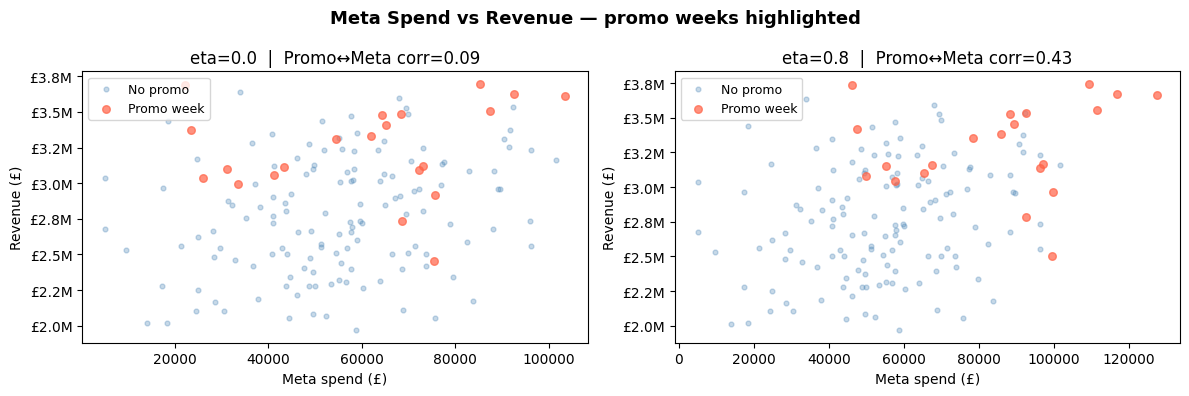

In [4]:
# Visualise: revenue in promo vs non-promo weeks, for clean vs stressed
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (eta, df) in zip(axes, [(0.0, df0), (0.8, df8)]):
    promo_mask = df['promo'] == 1
    ax.scatter(df.loc[~promo_mask, 'meta'], df.loc[~promo_mask, 'revenue'],
               alpha=0.3, s=12, label='No promo', color='steelblue')
    ax.scatter(df.loc[promo_mask, 'meta'], df.loc[promo_mask, 'revenue'],
               alpha=0.7, s=30, label='Promo week', color='tomato', zorder=5)
    ax.set_title(f'eta={eta}  |  Promo↔Meta corr={np.corrcoef(df["promo"], df["meta"])[0,1]:.2f}')
    ax.set_xlabel('Meta spend (£)')
    ax.set_ylabel('Revenue (£)')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'£{x/1e6:.1f}M'))
    ax.legend(fontsize=9)

fig.suptitle('Meta Spend vs Revenue — promo weeks highlighted', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Section 4 — fit_model() and Single Run

In [5]:
def fit_model(df: pd.DataFrame, include_promo: bool = True) -> dict:
    """
    Fit OLS MMM on df.

    Model A (include_promo=True)  : controls = trend, sin52, cos52, promo, meta, search, tv
    Model B (include_promo=False) : controls = trend, sin52, cos52,       meta, search, tv

    Returns dict with ROAS estimates, SEs, R², and 95% CI bounds.
    """
    regressors = ['trend', 'sin52', 'cos52', 'meta', 'search', 'tv']
    if include_promo:
        regressors = ['trend', 'sin52', 'cos52', 'promo', 'meta', 'search', 'tv']

    X = sm.add_constant(df[regressors])
    y = df['revenue']
    res = sm.OLS(y, X).fit()

    channels = ['meta', 'search', 'tv']
    out = {'r2': res.rsquared, 'model': 'A' if include_promo else 'B'}
    for ch in channels:
        coef = res.params[ch]
        se   = res.bse[ch]
        out[f'{ch}_roas_est'] = coef
        out[f'{ch}_roas_se']  = se
        out[f'{ch}_roas_lo']  = coef - 1.96 * se
        out[f'{ch}_roas_hi']  = coef + 1.96 * se
    return out

# Single run at eta=0.8
res_A = fit_model(df8, include_promo=True)
res_B = fit_model(df8, include_promo=False)

print('=== Single-run results (eta=0.8) ===')
header = f'{"Channel":8s}  {"True":>6s}  {"Model A":>10s}  {"Model B":>10s}'
print(header)
print('-' * len(header))
for ch in ['meta', 'search', 'tv']:
    true  = TRUE_ROAS[ch]
    a_est = res_A[f'{ch}_roas_est']
    b_est = res_B[f'{ch}_roas_est']
    print(f'{ch:8s}  {true:>6.2f}  {a_est:>10.3f}  {b_est:>10.3f}')

print(f'\nR² Model A={res_A["r2"]:.3f}   R² Model B={res_B["r2"]:.3f}')

=== Single-run results (eta=0.8) ===
Channel     True     Model A     Model B
----------------------------------------
meta        2.00       2.056       4.669
search      5.00       4.722       5.261
tv          1.50       1.547       1.538

R² Model A=0.981   R² Model B=0.899


## Section 5 — run_one_simulation()

In [6]:
def run_one_simulation(eta: float, seed: int) -> dict:
    """
    Generate data, fit both Model A and Model B, return combined results.
    """
    df, truth = generate_data(eta=eta, seed=seed)
    fit_A = fit_model(df, include_promo=True)
    fit_B = fit_model(df, include_promo=False)

    out = {'eta': eta, 'seed': seed}
    for label, fit in [('A', fit_A), ('B', fit_B)]:
        out[f'r2_{label}'] = fit['r2']
        for ch in ['meta', 'search', 'tv']:
            true_roas = TRUE_ROAS[ch]
            est  = fit[f'{ch}_roas_est']
            lo   = fit[f'{ch}_roas_lo']
            hi   = fit[f'{ch}_roas_hi']
            out[f'{ch}_roas_est_{label}']     = est
            out[f'{ch}_roas_bias_{label}']    = est - true_roas
            out[f'{ch}_pct_err_{label}']      = (est - true_roas) / true_roas
            out[f'{ch}_large_err_{label}']    = int(abs(est - true_roas) / true_roas > 0.50)
            out[f'{ch}_covers_truth_{label}'] = int(lo <= true_roas <= hi)
    return out

# Smoke test
test_sim = run_one_simulation(eta=0.0, seed=42)
print('Smoke test passed.')
print('Keys:', [k for k in test_sim.keys() if 'meta' in k])

Smoke test passed.
Keys: ['meta_roas_est_A', 'meta_roas_bias_A', 'meta_pct_err_A', 'meta_large_err_A', 'meta_covers_truth_A', 'meta_roas_est_B', 'meta_roas_bias_B', 'meta_pct_err_B', 'meta_large_err_B', 'meta_covers_truth_B']


## Section 6 — Clean-Case Baseline Monte Carlo (N=500)

In [7]:
print(f'Running {N_BASELINE} simulations at eta=0.0 (clean baseline)...')

baseline_results = []
for i in range(N_BASELINE):
    seed = MASTER_SEED + i
    baseline_results.append(run_one_simulation(eta=0.0, seed=seed))

baseline_df = pd.DataFrame(baseline_results)

print('\n=== Baseline Summary (eta=0.0) ===')
for label in ['A', 'B']:
    print(f'  -- Model {label} --')
    for ch in ['meta', 'search', 'tv']:
        mean_est = baseline_df[f'{ch}_roas_est_{label}'].mean()
        mean_bias = baseline_df[f'{ch}_roas_bias_{label}'].mean()
        p_large  = baseline_df[f'{ch}_large_err_{label}'].mean()
        coverage = baseline_df[f'{ch}_covers_truth_{label}'].mean()
        print(f'    {ch:6s}: mean_est={mean_est:.3f}  bias={mean_bias:+.3f}  '
              f'P(>50% err)={p_large:.3f}  coverage={coverage:.3f}')

print(f'\n  Mean R² A={baseline_df["r2_A"].mean():.3f}   Mean R² B={baseline_df["r2_B"].mean():.3f}')

Running 500 simulations at eta=0.0 (clean baseline)...

=== Baseline Summary (eta=0.0) ===
  -- Model A --
    meta  : mean_est=1.993  bias=-0.007  P(>50% err)=0.000  coverage=0.944
    search: mean_est=5.016  bias=+0.016  P(>50% err)=0.000  coverage=0.938
    tv    : mean_est=1.503  bias=+0.003  P(>50% err)=0.000  coverage=0.952
  -- Model B --
    meta  : mean_est=1.993  bias=-0.007  P(>50% err)=0.068  coverage=0.940
    search: mean_est=5.068  bias=+0.068  P(>50% err)=0.000  coverage=0.934
    tv    : mean_est=1.492  bias=-0.008  P(>50% err)=0.002  coverage=0.948

  Mean R² A=0.979   Mean R² B=0.896


## Section 7 — Stress Test Loop (N=300 per eta level)

In [8]:
print(f'Running stress test: {len(ETA_LEVELS)} eta levels × {N_STRESS} sims each...')

all_results = []
for eta in ETA_LEVELS:
    for i in range(N_STRESS):
        seed = MASTER_SEED + int(eta * 1_000_000) + i
        all_results.append(run_one_simulation(eta=eta, seed=seed))
    print(f'  eta={eta:.1f} done ({N_STRESS} sims)')

stress_df = pd.DataFrame(all_results)
print(f'\nTotal simulations: {len(stress_df)}')

Running stress test: 6 eta levels × 300 sims each...
  eta=0.0 done (300 sims)
  eta=0.2 done (300 sims)
  eta=0.4 done (300 sims)
  eta=0.6 done (300 sims)
  eta=0.8 done (300 sims)
  eta=1.0 done (300 sims)

Total simulations: 1800


## Section 8 — Summary Table

In [9]:
summary_rows = []
for eta in ETA_LEVELS:
    sub = stress_df[stress_df['eta'] == eta]
    row = {'eta': eta, 'n_sims': len(sub)}
    for label in ['A', 'B']:
        row[f'r2_{label}'] = sub[f'r2_{label}'].mean()
        for ch in ['meta', 'search', 'tv']:
            row[f'{ch}_mean_bias_{label}'] = sub[f'{ch}_roas_bias_{label}'].mean()
            row[f'{ch}_p_large_{label}']   = sub[f'{ch}_large_err_{label}'].mean()
            row[f'{ch}_coverage_{label}']  = sub[f'{ch}_covers_truth_{label}'].mean()
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
print('=== Stress Test Summary (selected columns) ===')
cols_to_show = ['eta', 'n_sims',
                'meta_mean_bias_A', 'meta_mean_bias_B',
                'meta_p_large_A',   'meta_p_large_B',
                'r2_A',             'r2_B']
display(summary_df[cols_to_show].round(3))

=== Stress Test Summary (selected columns) ===


,eta,n_sims,meta_mean_bias_A,meta_mean_bias_B,meta_p_large_A,meta_p_large_B,r2_A,r2_B
0,0.0,300,0.005,0.006,0.0,0.067,0.979,0.895
1,0.2,300,-0.005,0.419,0.0,0.117,0.979,0.898
2,0.4,300,0.012,0.899,0.0,0.380,0.980,0.901
3,0.6,300,-0.003,1.263,0.0,0.707,0.979,0.903
4,0.8,300,-0.006,1.608,0.0,0.850,0.980,0.909
5,1.0,300,0.021,1.936,0.0,0.993,0.980,0.912


## Section 9 — Main Chart: Confounder Correlation vs P(>50% ROAS Error)

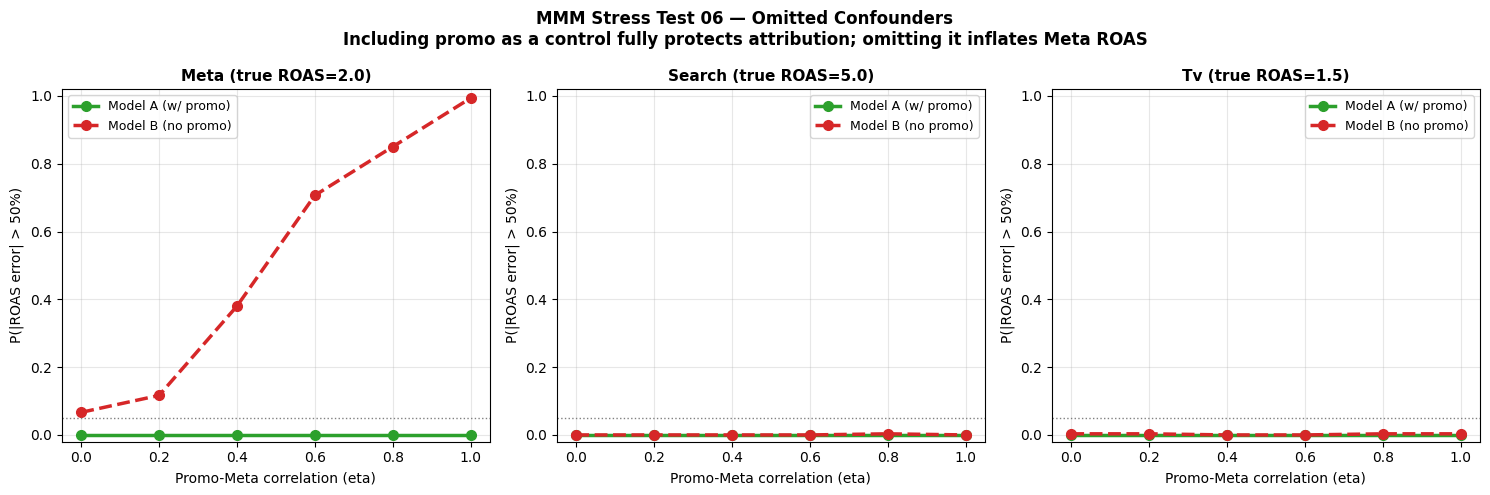

Saved: stress06_main_chart.png


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

colors_model = {'A': '#2ca02c', 'B': '#d62728'}
channel_colors = {'meta': '#1f77b4', 'search': '#ff7f0e', 'tv': '#2ca02c'}
linestyles = {'A': '-', 'B': '--'}

for ax, ch in zip(axes, ['meta', 'search', 'tv']):
    for label in ['A', 'B']:
        p_large = [summary_df.loc[summary_df['eta'] == e, f'{ch}_p_large_{label}'].values[0]
                   for e in ETA_LEVELS]
        ax.plot(
            ETA_LEVELS, p_large,
            color=colors_model[label],
            linestyle=linestyles[label],
            linewidth=2.5,
            marker='o',
            markersize=7,
            label=f'Model {label} ({"w/ promo" if label == "A" else "no promo"})'
        )
    ax.axhline(0.05, color='grey', linestyle=':', linewidth=1)
    ax.set_title(f'{ch.capitalize()} (true ROAS={TRUE_ROAS[ch]:.1f})', fontsize=11, fontweight='bold')
    ax.set_xlabel('Promo-Meta correlation (eta)', fontsize=10)
    ax.set_ylabel('P(|ROAS error| > 50%)', fontsize=10)
    ax.set_ylim(-0.02, 1.02)
    ax.set_xticks(ETA_LEVELS)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

fig.suptitle(
    'MMM Stress Test 06 — Omitted Confounders\n'
    'Including promo as a control fully protects attribution; omitting it inflates Meta ROAS',
    fontsize=12, fontweight='bold'
)
fig.tight_layout()
plt.savefig('stress06_main_chart.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: stress06_main_chart.png')

## Section 10 — Model Fit: Both Models Stay High

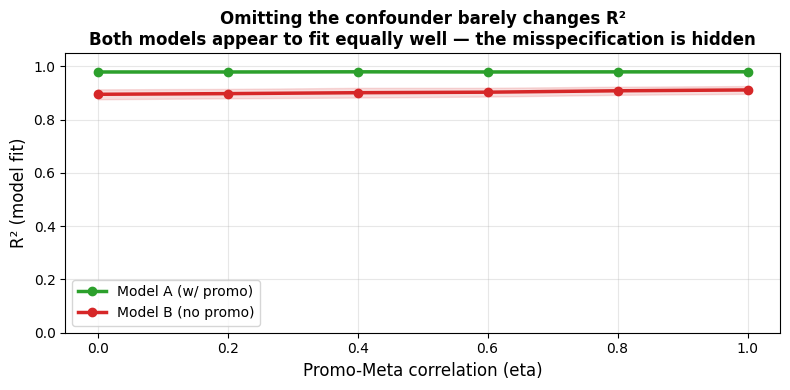

Saved: stress06_r2_chart.png


In [11]:
fig, ax = plt.subplots(figsize=(8, 4))

for label, color in [('A', '#2ca02c'), ('B', '#d62728')]:
    r2_by_eta = stress_df.groupby('eta')[f'r2_{label}'].agg(['mean', 'std']).reset_index()
    ax.fill_between(
        r2_by_eta['eta'],
        r2_by_eta['mean'] - r2_by_eta['std'],
        r2_by_eta['mean'] + r2_by_eta['std'],
        alpha=0.15, color=color
    )
    ax.plot(
        r2_by_eta['eta'], r2_by_eta['mean'],
        color=color, linewidth=2.5, marker='o',
        label=f'Model {label} ({"w/ promo" if label == "A" else "no promo"})'
    )

ax.set_xlabel('Promo-Meta correlation (eta)', fontsize=12)
ax.set_ylabel('R² (model fit)', fontsize=12)
ax.set_title(
    'Omitting the confounder barely changes R²\n'
    'Both models appear to fit equally well — the misspecification is hidden',
    fontsize=12, fontweight='bold'
)
ax.set_ylim(0, 1.05)
ax.set_xticks(ETA_LEVELS)
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.savefig('stress06_r2_chart.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: stress06_r2_chart.png')

## Section 11 — ROAS Uncertainty Ribbon Chart

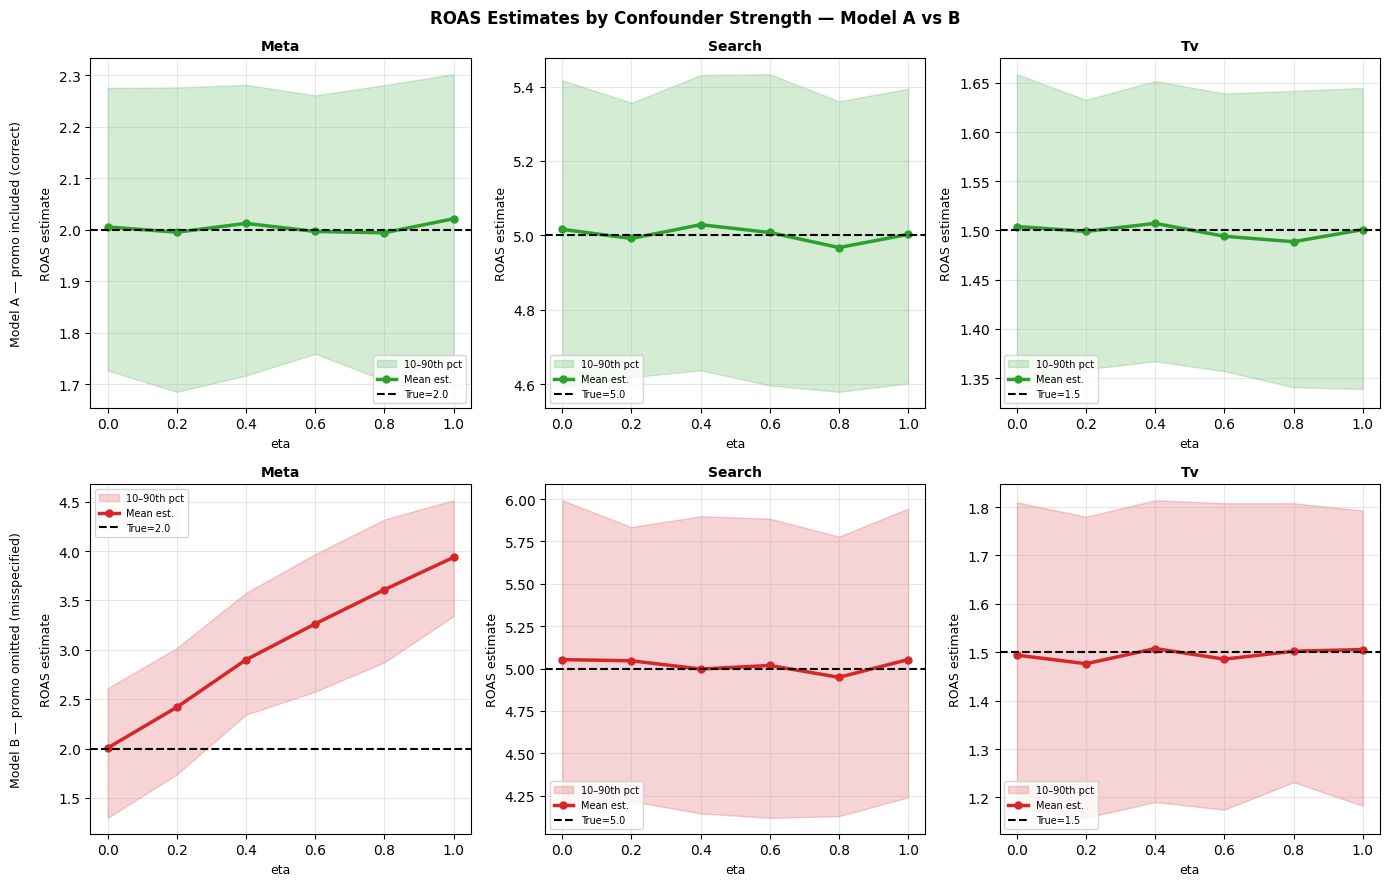

Saved: stress06_roas_ribbon.png


In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9), sharey=False)

model_labels = [('A', 'Model A — promo included (correct)'),
                ('B', 'Model B — promo omitted (misspecified)')]

row_colors = {'A': '#2ca02c', 'B': '#d62728'}

for row_idx, (label, row_title) in enumerate(model_labels):
    for col_idx, ch in enumerate(['meta', 'search', 'tv']):
        ax = axes[row_idx][col_idx]
        color = row_colors[label]

        grp = stress_df.groupby('eta')[f'{ch}_roas_est_{label}']
        mean_est = grp.mean()
        lo_est   = grp.quantile(0.10)
        hi_est   = grp.quantile(0.90)

        ax.fill_between(mean_est.index, lo_est.values, hi_est.values,
                        alpha=0.2, color=color, label='10–90th pct')
        ax.plot(mean_est.index, mean_est.values,
                color=color, linewidth=2.5, marker='o', markersize=5, label='Mean est.')
        ax.axhline(TRUE_ROAS[ch], color='black', linestyle='--',
                   linewidth=1.5, label=f'True={TRUE_ROAS[ch]}')

        ax.set_title(f'{ch.capitalize()}', fontsize=10, fontweight='bold')
        ax.set_xlabel('eta', fontsize=9)
        ax.set_ylabel('ROAS estimate', fontsize=9)
        ax.set_xticks(ETA_LEVELS)
        ax.legend(fontsize=7)
        ax.grid(True, alpha=0.3)

    axes[row_idx][0].set_ylabel(f'{row_title}\n\nROAS estimate', fontsize=9)

fig.suptitle('ROAS Estimates by Confounder Strength — Model A vs B',
             fontsize=12, fontweight='bold')
fig.tight_layout()
plt.savefig('stress06_roas_ribbon.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: stress06_roas_ribbon.png')

## Section 12 — Save CSVs

In [13]:
import os
os.makedirs('results', exist_ok=True)

stress_df.to_csv('results/stress06_all_sims.csv', index=False)
summary_df.to_csv('results/stress06_summary.csv', index=False)
baseline_df.to_csv('results/stress06_baseline.csv', index=False)

print('Saved:')
print('  results/stress06_all_sims.csv')
print('  results/stress06_summary.csv')
print('  results/stress06_baseline.csv')
print(f'\nTotal simulations: {len(stress_df)} stress + {len(baseline_df)} baseline')

Saved:
  results/stress06_all_sims.csv
  results/stress06_summary.csv
  results/stress06_baseline.csv

Total simulations: 1800 stress + 500 baseline
